<a href="https://colab.research.google.com/github/knou-park/DataAnalysis/blob/main/%EC%98%A4%ED%94%88%EC%86%8C%EC%8A%A4_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EB%B6%84%EC%84%9D_14%EA%B0%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 14강 비정형 데이터 분석 : 패션 사진 데이터 활용

### 목표

- 비정형 데이터를 인공지능 모델로 분석하여 실무에서 활용 가능한 보고서 형태로 가공

- 패션 트렌드라는 구체적인 주제를 통해, 비정형 데이터 분석의 실질적인 활용 방안을 경험하고자 함


### 분석 프로세스 개요

1. 데이터 수집
  - requests를 이용한 RSS 데이터 수집
  - lxml을 이용한 XML 파싱
  - 이미지 데이터 추출
2. VLM을 이용한 이미지 분석
  - 프롬프트를 이용한 이미지 필터링
  - 프롬프트를 이용한 스타일 분석
3. LLM을 이용한 키워드 분석 및 보고서 작성
  - 텍스트 전처리
  - 색상 및 스타일 키워드 추출
  - 워드 클라우드 분석
  - 보고서 작성

# 주의 : 런타임 GPU 로 설정 필요

In [ ]:
# 4bit VLM 처리를 위한 bitsandbytes 설치
# LLM 처리를 위한 VLLM 설치 (오래걸리는 작업(>5분)이므로 미리 실행!)
!pip install bitsandbytes==0.45.3 vllm==0.7.3 transformers==4.48.2
# 필요 시 세션 재시작

In [ ]:
# 한글 처리를 위한 matplotlib 설정 (1)

!sudo apt-get install -y fonts-nanum
!sudo fc-cache –fv
!rm ~/.cache/matplotlib -rf

- 런타임 -> 세션 다시 시작

In [1]:
# 한글 처리를 위한 matplotlib 설정 (2)

import matplotlib.pyplot as plt
plt.rc('font', family='NanumBarunGothic')

# 1. 데이터 수집 및 전처리

## 14-1 RSS 피드에서 이미지 URL 추출

In [1]:
import requests
from lxml import etree
from lxml.html import fromstring
import pandas as pd

def extract_unique_images(rss_url):
    ## 주어진 RSS 피드 URL에서 고유한 이미지 URL들을 추출하는 함수 정의
    try:
        ## requests 라이브러리를 사용하여 RSS 피드 URL로부터 내용을 가져옴
        response = requests.get(rss_url)
        ## 가져온 XML 응답 내용을 lxml의 etree.fromstring으로 파싱하여 XML 트리 root를 생성
        root = etree.fromstring(response.content)
        image_urls = set()

        ## XML 트리에서 모든 'item' 태그를 XPath를 사용하여 순회
        for item in root.xpath('//item'):
            description = item.find('description')
            if description is not None and description.text:
                ## description의 텍스트 내용을 lxml.html.fromstring으로 파싱하여 HTML 트리를 생성
                html_tree = fromstring(description.text)
                ## HTML 트리에서 첫 번째 <img> 태그의 'src' 속성 값을 XPath를 사용하여 추출
                img_url = html_tree.xpath('string(//img/@src)')
                if img_url:
                    image_urls.add(img_url)

        return list(image_urls)

    except Exception as e:
        ## 오류 발생 시 오류 메시지를 출력하고 빈 리스트를 반환
        print(f"Error occurred: {e}")
        return []

rss_url = "https://glltn.com/feed/"
## extract_unique_images 함수를 호출하여 고유한 이미지 URL들을 추출
unique_images = extract_unique_images(rss_url)

## 추출된 이미지 URL 리스트를 사용하여 'image'라는 열을 가진 pandas DataFrame을 생성
df = pd.DataFrame(unique_images, columns=["image"])

In [2]:
df

,image
0,https://glltn.com/wp-content/blogs.dir/1/files...
1,https://glltn.com/wp-content/blogs.dir/1/files...
2,https://glltn.com/wp-content/blogs.dir/1/files...
3,https://glltn.com/wp-content/blogs.dir/1/files...
4,https://glltn.com/wp-content/blogs.dir/1/files...
5,https://glltn.com/wp-content/blogs.dir/1/files...
6,https://glltn.com/wp-content/blogs.dir/1/files...
7,https://glltn.com/wp-content/blogs.dir/1/files...
8,https://glltn.com/wp-content/blogs.dir/1/files...
9,https://glltn.com/wp-content/blogs.dir/1/files...


## 14-2 수집 데이터 확인

In [3]:
from IPython.display import display, HTML

def path_to_image_html(path):
    ## 이미지 경로를 HTML img 태그로 변환하는 함수
    return f'<img src="{path}" width="300" />'

## DataFrame의 스타일을 설정하여 이미지 너비를 300px로 지정
df.style.set_table_styles([{'selector': 'img', 'props': 'width: 300px;'}])

## DataFrame을 HTML로 변환하여 출력. 이미지 열은 path_to_image_html 함수로 포맷팅
display(HTML(df.to_html(escape=False, formatters=dict(**{'image': path_to_image_html}))))

,image
0,
1,
2,
3,
4,
5,
6,
7,
8,
9,


## 2. VLM을 이용한 이미지 분석

## 14-3 VLM 모델 로드

In [ ]:
import torch
from PIL import Image
from transformers import AutoModel, AutoTokenizer

## 'openbmb/MiniCPM-V-2_6-int4' 모델을 사전 훈련된 가중치와 함께 로드
## trust_remote_code=True는 허브에서 사용자 정의 코드를 실행할 수 있도록 허용
model = AutoModel.from_pretrained('openbmb/MiniCPM-V-2_6-int4', trust_remote_code=True)
## 로드된 모델에 해당하는 토크나이저를 로드
tokenizer = AutoTokenizer.from_pretrained('openbmb/MiniCPM-V-2_6-int4', trust_remote_code=True)
## 모델을 평가 모드로 설정 (드롭아웃 등 훈련 시에만 필요한 기능 비활성화)
model.eval()

![](https://farm3.staticflickr.com/2677/4434956914_6e95a22940_z.jpg)

## 14-4 이미지 질문 응답 예시

In [5]:
from transformers import set_seed

## 재현성을 위해 시드(seed)를 42로 설정
set_seed(42)
## 예시 이미지 URL 정의
image_url = 'https://farm3.staticflickr.com/2677/4434956914_6e95a22940_z.jpg'
## requests로 이미지 다운로드 후 PIL Image 객체로 열고 RGB 형식으로 변환
image = Image.open(requests.get(image_url, stream=True).raw).convert('RGB')
## 이미지에 대한 질문 정의
question = 'how many cats in the photo?'
## 모델 입력 형식에 맞춰 메시지 구성 (이미지와 질문 포함)
msgs = [{'role': 'user', 'content': [image, question]}]
## 모델의 chat 함수를 호출하여 이미지와 질문에 대한 응답 생성
result = model.chat(image=None, msgs=msgs, tokenizer=tokenizer)
## 모델의 응답 출력
print(result)

preprocessor_config.json:   0%|          | 0.00/714 [00:00<?, ?B/s]

processing_minicpmv.py: 0.00B [00:00, ?B/s]

image_processing_minicpmv.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/openbmb/MiniCPM-V-2_6-int4:
- image_processing_minicpmv.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
A new version of the following files was downloaded from https://huggingface.co/openbmb/MiniCPM-V-2_6-int4:
- processing_minicpmv.py
- image_processing_minicpmv.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
/usr/local/lib/python3.12/dist-packages/transformers/models/auto/image_processing_auto.py:590: FutureWarning: The image_processor_class argument is deprecated and will be removed in v4.42. Please use `slow_image_processor_class`, or `fast_image_processor_class` instead
  warnings.warn(
Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=

1


In [6]:
set_seed(42)
## 이미지에 대한 질문을 업데이트. 책 표지의 고양이도 포함하도록 요청
question = 'how many cats in the photo? including the books cover.'
## 모델 입력 형식에 맞춰 메시지 구성 (이전에 로드된 이미지와 업데이트된 질문 포함)
msgs = [{'role': 'user', 'content': [image, question]}]
## 모델의 chat 함수를 호출하여 업데이트된 질문에 대한 응답 생성
result = model.chat(image=None, msgs=msgs, tokenizer=tokenizer)
## 모델의 응답 출력
print(result)

1


In [7]:
set_seed(42)
## 이미지에 대한 질문을 'describe the photo'로 설정하여 이미지 내용을 설명하도록 요청
question = 'describe the photo'
## 모델 입력 형식에 맞춰 메시지 구성 (이전에 로드된 이미지와 설명 요청 질문 포함)
msgs = [{'role': 'user', 'content': [image, question]}]
## 모델의 chat 함수를 호출하여 이미지에 대한 설명을 생성
result = model.chat(image=None, msgs=msgs, tokenizer=tokenizer)
## 모델의 응답 (이미지 설명) 출력
print(result)

The photo shows a book with the title "why dogs are better than cats" and an image of a cat on top of a dog's head. To the right of the book, there is a real cat standing on a wooden surface, seemingly observing or reacting to the book. The cat has striped fur and appears attentive.


## 14-5 의류 이미지 여부 판단

In [8]:
def is_picture_of_clothing(image_url):
    ## 이미지 URL이 의류 사진인지 판단하는 함수
    # 의류가 포함된 사진인지 확인하는 질문 작성 (영어로)
    question = 'Is this a picture of clothing? MUST say yes or no.'
    image = Image.open(requests.get(image_url, stream=True).raw).convert('RGB')
    msgs = [{'role': 'user', 'content': [image, question]}]
    result = model.chat(image=None, msgs=msgs, tokenizer=tokenizer, temperature=0.1)
    print(result)
    ## 응답에 'yes'가 포함되어 있는지 확인하여 True/False 반환
    return 'yes' in result.lower()

## DataFrame의 'image' 열에 함수를 적용하여 'is_clothing' 열에 결과 저장
df['is_clothing'] = df['image'].apply(is_picture_of_clothing)

No.
No.
Yes, this image appears to be a fashion-oriented photograph showcasing clothing. The focus on the individual's attire and the styling suggests that it could be used for fashion retail or editorial purposes, where the aim is to display clothing in an appealing way.
Yes, this image is of clothing. It showcases a coordinated outfit consisting of a jacket and shorts with a distinctive pattern of black crosses on a cream-colored fabric. The attire appears to be designed for casual wear, possibly targeting a youthful demographic given the playful nature of the cross motifs. The presentation style, with the model posing against a neutral background, suggests that this could be from a fashion catalog or a lookbook intended to display the garments in a visually appealing manner.
Yes, this image is of clothing. It features a coat that appears to be designed for cold weather, given its thick material and the presence of what seems to be a shearling collar, which is often used in outerwear

## 14-6 의류 판단 결과 시각화

In [9]:
display(HTML(df.to_html(escape=False, formatters=dict(**{'image': path_to_image_html}))))

,image,is_clothing
0,,False
1,,False
2,,True
3,,True
4,,True
5,,False
6,,True
7,,True
8,,False
9,,True


## 14-7 의류 이미지 필터링

In [10]:
## 'is_clothing' 열의 값이 True인 행들만 필터링하여 DataFrame을 업데이트
df = df[df['is_clothing']]

In [11]:
display(HTML(df.to_html(escape=False, formatters=dict(**{'image': path_to_image_html}))))

,image,is_clothing
2,,True
3,,True
4,,True
6,,True
7,,True
9,,True
10,,True
11,,True


## 14-8 의류 스타일 분석

In [12]:
def describe_style(image_url):
    ## 주어진 이미지 URL의 의류 스타일을 분석하는 함수
    question = 'Analyze the style of the clothes. Please let me explain the colors and trend changes.'
    image = Image.open(requests.get(image_url, stream=True).raw).convert('RGB')
    msgs = [{'role': 'user', 'content': [image, question]}]
    ## 모델의 chat 함수를 호출하여 이미지에 대한 스타일 분석 응답 생성
    result = model.chat(image=None, msgs=msgs, tokenizer=tokenizer)
    return result

## 필터링된 DataFrame의 'image' 열에 describe_style 함수를 적용
## 결과는 'style'이라는 새로운 열에 저장
df['style'] = df['image'].apply(describe_style)

/tmp/ipykernel_5065/1874085826.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['style'] = df['image'].apply(describe_style)


In [13]:
display(HTML(df.to_html(escape=False, formatters=dict(**{'image': path_to_image_html}))))

,image,is_clothing,style
2,,True,"The style of the clothes in the image suggests a contemporary, casual-chic aesthetic that is often seen in modern fashion. The use of neutral colors like grey and black is a common trend as it provides versatility and can be easily mixed and matched with other items. The knitted cardigan adds texture and depth to the outfit, indicating an appreciation for layering which is both practical and stylish.\n\nThe rolled-up sleeves on the shirt suggest a relaxed yet thoughtful approach to dressing, showing attention to detail without being overly formal. This style choice could indicate a preference for comfort while still maintaining a polished look. The overall ensemble appears timeless rather than trendy, focusing on classic pieces that are likely to remain fashionable over time.\n\nIn terms of color trends, neutrals have been consistently popular due to their ability to create a calm and sophisticated appearance. The combination of these colors with the textured knitwear reflects a current trend towards comfort-oriented fashion that doesn't sacrifice style."
3,,True,"The clothing in the image reflects a casual and possibly youthful style, characterized by its relaxed fit and neutral color palette. The off-white or cream color of both the jacket and shorts suggests a preference for soft, understated tones that can be versatile for various settings. The presence of black crosses on both pieces adds a subtle yet distinctive detail that could indicate a nod to minimalist fashion trends where small embellishments make a statement without overwhelming the simplicity of the garment.\n\nThe trend changes here seem to favor comfort and ease of movement, as evidenced by the loose-fitting nature of the outfit. This aligns with contemporary fashion movements that prioritize functionality and personal expression over restrictive formal wear. Additionally, the choice of a monochromatic scheme with contrasting details is a common trend in modern casual wear, allowing for a clean and sophisticated look while still being approachable and stylish."
4,,True,"The style of the clothes in the image suggests a blend of classic and contemporary fashion trends. The coat's plaid pattern, featuring earthy tones like orange, brown, and beige, is reminiscent of traditional autumnal or fall fashion, often associated with comfort and warmth. The use of what appears to be shearling for the collar adds a modern twist to this classic design, providing both aesthetic appeal and functional warmth.\n\nThe layering underneath, including a visible red garment that could be a sweater or shirt, indicates an approach to dressing that prioritizes comfort and practicality, which is particularly relevant during colder seasons. This layered look has seen a resurgence in popularity as it allows for adjustments based on changing temperatures throughout the day.\n\nOverall, the outfit reflects a casual yet stylish approach to winter wear, where functionality meets fashion through the combination of timeless patterns and modern materials."
6,,True,"The boots in the image reflect a classic and somewhat rugged style, often associated with outdoor or workwear. The combination of leather and suede materials suggests a design that values durability as well as aesthetic appeal. Leather is known for its longevity and resistance to wear, making it a popular choice for footwear meant to withstand various conditions.\n\nThe brown color of both materials gives the boots a timeless look that can be easily paired with different outfits. Brown is a versatile color that complements a wide range of clothing colors and styles, from casual to more formal attire. It's also a common color in seasonal collections, indicating that these boots could fit into multiple fashion trends over time.\n\nIn terms of trend changes, this style of boot has seen periods of popularity and decline before experiencing revivals. They are currently enjoying renewed interest due to thei

In [14]:
df.to_pickle('data.pkl')

# 3. LLM을 이용한 키워드 분석 및 보고서 작성

## 14-9 언어 모델(LLM) 로드

In [ ]:
!pip install vllm

In [2]:
%pip uninstall -y torchaudio

Found existing installation: torchaudio 2.11.0+cu128
Uninstalling torchaudio-2.11.0+cu128:
  Successfully uninstalled torchaudio-2.11.0+cu128


In [5]:
!pip install torchaudio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 26.0 MB/s eta 0:00:00


In [9]:
import importlib.metadata as md
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("TorchAudio:", md.version("torchaudio"))

PyTorch: 2.13.0+cu130
CUDA: 13.0
TorchAudio: 2.11.0


In [12]:
!pip install --force-reinstall --no-deps \
  torchaudio==2.11.0 \
  --index-url https://download.pytorch.org/whl/cu130

Looking in indexes: https://download.pytorch.org/whl/cu130
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 26.3 MB/s eta 0:00:00
  Attempting uninstall: torchaudio
    Found existing installation: torchaudio 2.11.0
    Uninstalling torchaudio-2.11.0:
      Successfully uninstalled torchaudio-2.11.0


In [1]:
from vllm import LLM, SamplingParams

## vLLM 라이브러리를 사용하여 'LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct' 모델을 로드
## gpu_memory_utilization은 GPU 메모리 사용 비율을 0.5로 설정
## max_model_len은 모델이 처리할 수 있는 최대 토큰 길이를 10000으로 설정
llm = LLM(model = 'LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct', trust_remote_code=True, gpu_memory_utilization = 0.5, max_model_len = 10000)

(MainProcess pid=10279) INFO 10-22 01:32:00 [api_utils.py:286] non-default args: {'trust_remote_code': True, 'max_model_len': 10000, 'gpu_memory_utilization': 0.5, 'disable_log_stats': True, 'model': 'LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct'}


config.json:   0%|          | 0.00/1.04k [00:00<?, ?B/s]

configuration_exaone.py:   0%|          | 0.00/11.3k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct:
- configuration_exaone.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


(MainProcess pid=10279) INFO 10-22 01:32:25 [model.py:733] Resolved architecture: ExaoneForCausalLM
(MainProcess pid=10279) INFO 10-22 01:32:25 [model.py:2495] Downcasting torch.float32 to torch.float16.
(MainProcess pid=10279) INFO 10-22 01:32:25 [model.py:2152] Using max model len 10000
(MainProcess pid=10279) INFO 10-22 01:32:25 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.


...

(EngineCore pid=10713) INFO 10-22 01:34:39 [backends.py:398] [backbone] Compiling a graph for compile range (1, 8192) takes 10.84 s
(EngineCore pid=10713) INFO 10-22 01:34:45 [backends.py:927] collected artifacts: 31 entries, 3 artifacts, 4607240 bytes total
(EngineCore pid=10713) INFO 10-22 01:34:45 [decorators.py:743] [backbone] saved AOT compiled function to /root/.cache/vllm/torch_compile_cache/torch_aot_compile/62d9f39b1fa0551083293f606524a8c8c81e6db512208a469f867c3b3b4b7d62/rank_0_0/model
(EngineCore pid=10713) INFO 10-22 01:34:45 [monitor.py:62] [backbone] torch.compile took 24.81 s in total
(EngineCore pid=10713) INFO 10-22 01:34:45 [monitor.py:91] [backbone] Initial profiling/warmup run took 0.13 s


Capturing CUDA graphs (FULL): 100%|██████████| 2/2 [00:00<00:00,  7.81it/s]


(EngineCore pid=10713) INFO 10-22 01:35:00 [model_runner.py:1127] Graph capturing finished in 12 secs, took 0.31 GiB
(EngineCore pid=10713) INFO 10-22 01:35:01 [gpu_worker.py:759] Available KV cache memory: 1.58 GiB
(EngineCore pid=10713) INFO 10-22 01:35:01 [gpu_worker.py:774] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.5000 is equivalent to --gpu-memory-utilization=0.4751 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.5249. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(EngineCore pid=10713) INFO 10-22 01:35:01 [kv_cache_utils.py:2327] GPU KV cache size: 22,144 tokens, Maximum concurrency for 10,000 tokens per request: 2.21x
(EngineCore pid=10713) INFO 10-22 01:35:01 [kernel_warmup.py:176] JIT kernel warmup starting.
(EngineCore pid=10713) INFO 10-22 01:35:01 [kernel_warmup.py:189] JIT kernel warmup finished in 0.00s.


Capturing CUDA graphs (FULL): 100%|██████████| 35/35 [00:02<00:00, 12.36it/s]


(EngineCore pid=10713) INFO 10-22 01:35:36 [model_runner.py:1127] Graph capturing finished in 10 secs, took 0.19 GiB
(EngineCore pid=10713) INFO 10-22 01:35:37 [gpu_worker.py:971] CUDA graph pool memory: 0.19 GiB (actual), 0.36 GiB (estimated), difference: 0.18 GiB (95.8%).
(EngineCore pid=10713) INFO 10-22 01:35:37 [gpu_worker.py:1034] Free memory on device (14.46/14.56 GiB) on startup. Desired GPU memory utilization is (0.5, 7.28 GiB). Actual usage is 4.78 GiB for consumed memory (weights + non-torch), 0.92 GiB for peak activation, and 0.19 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=1344722432` (1.25 GiB) to fit into requested memory, or `--kv-cache-memory=9053296128` (8.43 GiB) to fully utilize gpu memory. Current kv cache memory in use is 1.58 GiB.
(EngineCore pid=10713) INFO 10-22 01:35:38 [jit_monitor.py:84] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(EngineCore pid=10713) INFO 10-22 0

In [2]:
import pandas as pd
df = pd.read_pickle('data.pkl')

In [3]:
df

,image,is_clothing,style
2,https://glltn.com/wp-content/blogs.dir/1/files...,True,The style of the clothes in the image suggests...
3,https://glltn.com/wp-content/blogs.dir/1/files...,True,The clothing in the image reflects a casual an...
4,https://glltn.com/wp-content/blogs.dir/1/files...,True,The style of the clothes in the image suggests...
6,https://glltn.com/wp-content/blogs.dir/1/files...,True,The boots in the image reflect a classic and s...
7,https://glltn.com/wp-content/blogs.dir/1/files...,True,The style of the clothes in the image suggests...
9,https://glltn.com/wp-content/blogs.dir/1/files...,True,The clothing style depicted in the image is ca...
10,https://glltn.com/wp-content/blogs.dir/1/files...,True,The style of the clothes in the image leans to...
11,https://glltn.com/wp-content/blogs.dir/1/files...,True,The style of the clothes in the image suggests...


## 14-10 색상 정보 추출

In [4]:
from vllm import SamplingParams ## SamplingParams 임포트가 필요

def extract_color(style):
  ## 주어진 스타일 설명 텍스트에서 색상을 한글로 추출하는 함수
  prompt = [
      {
          "role": "system",
          "content": "You are EXAONE model from LG AI Research, a helpful assistant."
      },
      {
          "role": "user",
          "content": f"다음의 글에서 색상을 한글로 추출해주세요. 색상 외에 다른 정보는 적지 말아주세요.\n{style}" # vlm이 작성한 글에서 색상 정보 추출, 한글로 번역하면서
      }
  ]
  ## 샘플링 파라미터 설정 (온도, top_p, 최대 토큰 수)
  sampling_params = SamplingParams(temperature=0.2, top_p=0.95, max_tokens=1024)
  ## LLM 모델을 사용하여 프롬프트에 대한 응답 생성
  result = llm.chat(prompt, sampling_params)[0].outputs[0].text
  print(result)
  return result

## DataFrame의 'style' 열에 extract_color 함수를 적용
## 결과는 'color'라는 새로운 열에 저장
df['color'] = df['style'].apply(extract_color)

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:03<00:00,  3.48s/it, est. speed input: 73.59 toks/s, output: 3.45 toks/s]

**색상:**
- 회색
- 검정색


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  4.07it/s, est. speed input: 945.60 toks/s, output: 37.00 toks/s]

...

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  4.71it/s, est. speed input: 1363.88 toks/s, output: 33.49 toks/s]

색상: 검정색, 회색


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  4.34it/s, est. speed input: 1060.16 toks/s, output: 35.19 toks/s]

- 베이지색 (Beige)


## 14-11 스타일 키워드 추출

In [5]:
from vllm import SamplingParams ## SamplingParams 임포트가 필요

def extract_style(style):
  ## 주어진 스타일 설명 텍스트에서 스타일 키워드를 한글로 추출하는 함수
  prompt = [
      {
          "role": "system",
          "content": "You are EXAONE model from LG AI Research, a helpful assistant."
      },
      {
          "role": "user",
          "content": f"다음의 글에서 스타일 키워드를 한글로 추출해주세요. 스타일 키워드 외에 다른 정보는 적지 말아주세요.\n{style}" # vlm이 작성한 글에서 스타일 키워드 추출, 한글로 번역하면서
      }
  ]
  ## 샘플링 파라미터 설정 (온도, top_p, 최대 토큰 수)
  sampling_params = SamplingParams(temperature=0.2, top_p=0.95, max_tokens=1024)
  ## LLM 모델을 사용하여 프롬프트에 대한 응답 생성
  result = llm.chat(prompt, sampling_params)[0].outputs[0].text
  print(result)
  return result

## DataFrame의 'style' 열에 extract_color 함수를 적용 (함수 이름은 이전과 동일하지만 기능 변경)
## 결과는 'keyword'라는 새로운 열에 저장
df['keyword'] = df['style'].apply(extract_color)

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  3.11it/s, est. speed input: 801.31 toks/s, output: 37.56 toks/s]

**색상:**
- 회색
- 검정색


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  4.82it/s, est. speed input: 1126.90 toks/s, output: 44.09 toks/s]

...

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  6.81it/s, est. speed input: 1972.53 toks/s, output: 41.52 toks/s]

색상: 검은색, 회색


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  5.43it/s, est. speed input: 1334.47 toks/s, output: 44.29 toks/s]

- 베이지색 (Beige)


In [8]:
from IPython.display import display, HTML

def path_to_image_html(path):
    ## 이미지 경로를 HTML img 태그로 변환하는 함수
    return f'<img src="{path}" width="300" />'

## DataFrame의 스타일을 설정하여 이미지 너비를 300px로 지정
df.style.set_table_styles([{'selector': 'img', 'props': 'width: 300px;'}])

## DataFrame을 HTML로 변환하여 출력. 이미지 열은 path_to_image_html 함수로 포맷팅
display(HTML(df.to_html(escape=False, formatters=dict(**{'image': path_to_image_html}))))

,image,is_clothing,style,color,keyword
2,,True,"The style of the clothes in the image suggests a contemporary, casual-chic aesthetic that is often seen in modern fashion. The use of neutral colors like grey and black is a common trend as it provides versatility and can be easily mixed and matched with other items. The knitted cardigan adds texture and depth to the outfit, indicating an appreciation for layering which is both practical and stylish.\n\nThe rolled-up sleeves on the shirt suggest a relaxed yet thoughtful approach to dressing, showing attention to detail without being overly formal. This style choice could indicate a preference for comfort while still maintaining a polished look. The overall ensemble appears timeless rather than trendy, focusing on classic pieces that are likely to remain fashionable over time.\n\nIn terms of color trends, neutrals have been consistently popular due to their ability to create a calm and sophisticated appearance. The combination of these colors with the textured knitwear reflects a current trend towards comfort-oriented fashion that doesn't sacrifice style.",**색상:**\n- 회색\n- 검정색,**색상:**\n- 회색\n- 검정색
3,,True,"The clothing in the image reflects a casual and possibly youthful style, characterized by its relaxed fit and neutral color palette. The off-white or cream color of both the jacket and shorts suggests a preference for soft, understated tones that can be versatile for various settings. The presence of black crosses on both pieces adds a subtle yet distinctive detail that could indicate a nod to minimalist fashion trends where small embellishments make a statement without overwhelming the simplicity of the garment.\n\nThe trend changes here seem to favor comfort and ease of movement, as evidenced by the loose-fitting nature of the outfit. This aligns with contemporary fashion movements that prioritize functionality and personal expression over restrictive formal wear. Additionally, the choice of a monochromatic scheme with contrasting details is a common trend in modern casual wear, allowing for a clean and sophisticated look while still being approachable and stylish.",색상:\n- 오프화이트/크림,색상:\n- 흰색/크림색
4,,True,"The style of the clothes in the image suggests a blend of classic and contemporary fashion trends. The coat's plaid pattern, featuring earthy tones like orange, brown, and beige, is reminiscent of traditional autumnal or fall fashion, often associated with comfort and warmth. The use of what appears to be shearling for the collar adds a modern twist to this classic design, providing both aesthetic appeal and functional warmth.\n\nThe layering underneath, including a visible red garment that could be a sweater or shirt, indicates an approach to dressing that prioritizes comfort and practicality, which is particularly relevant during colder seasons. This layered look has seen a resurgence in popularity as it allows for adjustments based on changing temperatures throughout the day.\n\nOverall, the outfit reflects a casual yet stylish approach to winter wear, where functionality meets fashion through the combination of timeless patterns and modern materials.",- **오렌지** (Orange)\n- **갈색** (Brown)\n- **베이지** (Beige)\n- **빨강** (Red),- 오렌지\n- 갈색\n- 베이지
6,,True,"The boots in the image reflect a classic and somewhat rugged style, often associated with outdoor or workwear. The combination of leather and suede materials suggests a design that values durability as well as aesthetic appeal. Leather is known for its longevity and resistance to wear, making it a popular choice for footwear meant to withstand various conditions.\n\nThe brown color of both materials gives the boots a timeless look that can be easily paired with different outfits. Brown is a versatile color that complements a wide range of clothing colors and styles, from casual to more formal attire. It's also a common color in seasonal collections, indicating that these boots could fit into multiple fashion trends over time.\n

## 14-12 텍스트 데이터 정제

In [9]:
import re

def clean_text(text):
    ## 텍스트에서 특수 문자 및 HTML 태그를 제거하고 소문자로 변환하는 함수
    if isinstance(text, str):
       ## 영문, 숫자, 한글, 공백을 제외한 모든 문자 제거
       text = re.sub(r'[^a-zA-Z0-9가-힣\s]', '', text)
       ## HTML 태그 제거
       text = re.sub(r'<[^>]*>', '', text)
       ## 텍스트를 소문자로 변환
       text = text.lower()
       return text
    else:
        return ""

## 'color' 열의 텍스트 데이터 정제
df['color'] = df['color'].apply(clean_text)
## 'keyword' 열의 텍스트 데이터 정제
df['keyword'] = df['keyword'].apply(clean_text)

## 14-13 워드 클라우드 생성 및 시각화

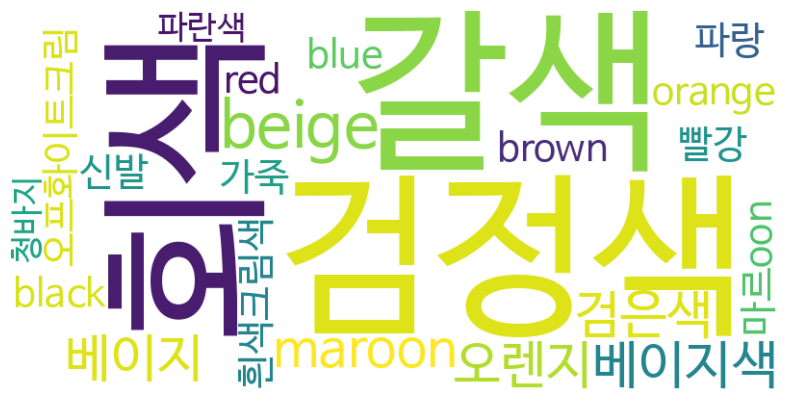

In [10]:
from collections import Counter
from wordcloud import WordCloud
import matplotlib.pyplot as plt

def get_word_count(df):
    ## DataFrame의 'color'와 'keyword' 열에서 단어 빈도를 계산하는 함수
    if not df.empty:
        ## 'color' 열의 모든 단어를 리스트로 합침
        all_nouns = df['color'].apply(str.split).sum()
        ## 'keyword' 열의 모든 단어를 추가
        all_nouns += df['keyword'].apply(str.split).sum()
        ## '색상' 단어를 제외한 모든 단어를 필터링
        all_nouns = [word for word in all_nouns if word not in ['색상']]
        ## 단어 빈도를 Counter 객체로 반환
        return Counter(all_nouns)
    return Counter() ## DataFrame이 비어있으면 빈 Counter 반환

def create_wordcloud(word_count):
    ## 단어 빈도수를 기반으로 워드 클라우드를 생성하고 시각화하는 함수
    if not word_count: ## 단어 빈도가 없으면 워드클라우드 생성하지 않음
        print("No words to generate word cloud.")
        return

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white',
        colormap='viridis',
        font_path='/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf' ## 한글 폰트 경로 지정
        ).generate_from_frequencies(word_count)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off") ## 축 표시 제거
    plt.show() ## 워드 클라우드 출력

## DataFrame에서 단어 빈도 계산
word_count = get_word_count(df)
## 계산된 단어 빈도로 워드 클라우드 생성 및 시각화
create_wordcloud(word_count)

## 14-14 트렌드 분석 보고서 생성 프롬프트 구성 및 실행

## 14-15 분석 보고서 시각화

In [11]:
from vllm import SamplingParams ## SamplingParams 임포트가 필요

## 시스템 메시지로 시작하는 프롬프트 리스트 초기화
prompt = [
    {
        "role": "system",
        "content": "You are EXAONE model from LG AI Research, a helpful assistant."
    }
]
## DataFrame의 각 행을 순회하며 '스타일 노트'와 '이미지 URL'을 사용자 메시지로 추가
for row in df.itertuples():
  prompt.append({"role": "user", "content": f"스타일 노트: {row.style}\n이미지 url: {row.image}"})
## 마지막으로, 종합적인 트렌드 분석 보고서 작성을 요청하는 사용자 메시지 추가
## 보고서 제목, 내용의 전문성, 마크다운 형식, 예시 이미지 포함을 지시
prompt.append({"role": "user", "content": "주어진 스타일 노트를 토대로 종합적인 트랜드 방향의 분석 보고서를 작성해주세요. 보고서의 제목은 해외 룩북 스타일 분석입니다. 내용은 전문적이면서 명확하게 작성해주세요. 문서 형식은 markdown으로 만들어주세요."})

## 샘플링 파라미터 설정 (온도, top_p, 최대 토큰 수)
sampling_params = SamplingParams(temperature=0.2, top_p=0.95, max_tokens=4096)
## LLM 모델을 사용하여 구성된 프롬프트에 대한 응답 생성
result = llm.chat(prompt, sampling_params)[0].outputs[0].text

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:32<00:00, 32.94s/it, est. speed input: 69.90 toks/s, output: 30.88 toks/s]


In [12]:
from IPython.display import display, Markdown

## LLM으로부터 생성된 결과(Markdown 형식의 보고서)를 Jupyter 환경에 표시
display(Markdown(result))

# 해외 룩북 스타일 분석 보고서

## 요약
본 보고서는 최근 공개된 여러 해외 패션 룩북에서 관찰되는 주요 트렌드를 종합적으로 분석하고, 이를 통해 현재 패션 산업의 방향성을 제시합니다. 주요 트렌드는 전통과 현대성의 융합, 기능성과 스타일의 조화, 그리고 다양한 문화적 영감의 적용으로 요약됩니다.

## 트렌드 분석

### 1. 전통과 현대성의 융합
- **예시**:
  - **일본 스타일**: 전통적인 기모노의 요소를 현대적인 캐주얼 룩에 접목시킨 디자인 (예: [Yandsons Fall Winter 2026 Collection Lookbook](https://glltn.com/wp-content/blogs.dir/1/files/2026/10/yandsons-fall-winter-2026-collection-lookbook-22-1024x683.jpg))
  - **군복 스타일**: 클래식한 군복 요소를 현대적인 캐주얼웨어에 통합 (예: [Haversack Fall Winter 2026 Collection Lookbook](https://glltn.com/wp-content/blogs.dir/1/files/2026/10/haversack-fall-winter-2026-collection-lookbook-10-1024x683.jpg))

  **분석**: 이러한 융합은 과거의 문화적 유산을 현대적 맥락에 맞게 재해석하여, 고유한 정체성과 동시에 폭넓은 패션적 표현력을 제공합니다.

### 2. 기능성과 스타일의 조화
- **예시**:
  - **실용적 코트**: 내구성과 실용성을 강조한 코트 디자인 (예: [Visvim Fall Winter 2026 Collection Lookbook](https://glltn.com/wp-content/blogs.dir/1/files/2026/10/visvim-fall-winter-2026-dunson-boots-folk-01-1024x683.jpg))
  - **편안한 데님**: distressed denim과 레이어링을 통한 실용적이고 스타일리시한 룩 (예: [Deluxe Fall Winter 2026 Collection Lookbook](https://glltn.com/wp-content/blogs.dir/1/files/2026/10/deluxe-fall-winter-2026-suicoke-fuck-off-moccasin-01-1024x683.jpg))

  **분석**: 현대 소비자들은 기능성과 스타일을 동시에 추구하며, 이러한 트렌드는 편안함과 실용성을 유지하면서도 패션적 완성도를 높이는 방향으로 패션 산업을 이끌고 있습니다.

### 3. 다양한 문화적 영감의 적용
- **예시**:
  - **스트리트웨어와 전통**: 스트리트웨어 요소와 전통적인 디자인의 결합 (예: [Bru Na Boinne Fall Winter 2026 Collection Lookbook](https://glltn.com/wp-content/blogs.dir/1/files/2026/10/bru-na-boinne-fall-winter-2026-collection-lookbook-15-1024x683.jpg))
  - **실용적 전통**: 전통적인 패턴과 현대적인 소재의 조합 (예: [Needles Pendleton Fall Winter 2026 Collection Lookbook](https://glltn.com/wp-content/blogs.dir/1/files/2026/10/needles-pendleton-fall-winter-2026-collection.-lookbook-07-1024x683.jpg))

  **분석**: 다양한 문화적 요소의 융합은 글로벌화된 패션 시장에서 독특한 아이덴티티를 창출하고, 소비자들에게 폭넓은 선택의 폭을 제공합니다.

## 결론
현재 패션 트렌드는 과거의 유산을 현대적으로 재해석하고, 기능성과 스타일의 균형을 추구하며, 다양한 문화적 영감을 통합하는 방향으로 진화하고 있습니다. 이러한 접근법은 패션을 단순한 의복을 넘어 개인의 표현과 사회적 맥락을 반영하는 강력한 도구로 자리매김하게 합니다. 패션 브랜드와 디자이너들은 이러한 트렌드를 적극적으로 수용하고 혁신적인 디자인으로 발전시켜 나갈 필요가 있습니다.